# Task 4 — Dimensionality Reduction & Unsupervised Clustering

**Objective:** standardize numerical features, use PCA to inspect explained variance, evaluate K-Means cluster counts using inertia and silhouette scores, and compare with DBSCAN and hierarchical clustering.

**Dataset:** UCI Student Performance Mathematics (`student-mat.csv`).

**Important:** this is exploratory unsupervised learning. We do not use `G3` (final grade) to create clusters, to avoid using the main outcome as an input. We can describe the resulting groups afterward, but should not claim that clusters are objectively true student categories.

## 1. Imports and load dataset

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.impute import SimpleImputer

sns.set_theme(style="whitegrid", context="notebook")
DATA_PATH = Path("../data/raw/student-mat.csv")
if not DATA_PATH.exists():
    # Also allow running from the project root
    DATA_PATH = Path("data/raw/student-mat.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place student-mat.csv in data/raw/ before running this notebook."
    )

df = pd.read_csv(DATA_PATH, sep=";")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Select numerical features and standardize

In [2]:
# Use numerical columns only; exclude G3 so final grade does not drive clustering.
numeric = df.select_dtypes(include=np.number).copy()
if "G3" in numeric.columns:
    numeric = numeric.drop(columns=["G3"])
# G1 and G2 are earlier grades, so they remain numeric clustering features.
# Drop constant columns if any, then impute missing values defensively.
numeric = numeric.loc[:, numeric.nunique(dropna=True) > 1]
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(numeric)
feature_names = numeric.columns.tolist()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Rows:", X_scaled.shape[0])
print("Numerical features used:", len(feature_names))
print(feature_names)

Rows: 395
Numerical features used: 15
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


## 3. PCA and explained variance (scree plot)

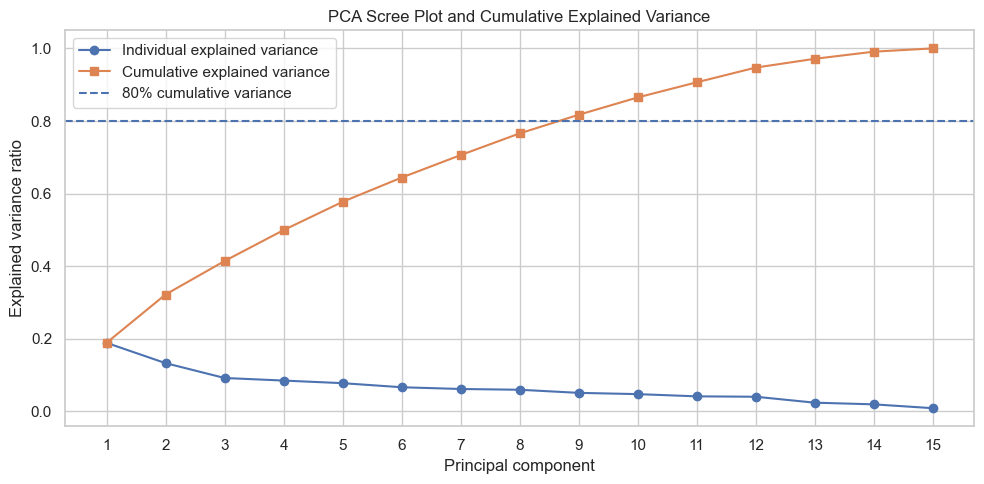

Components needed to reach at least 80% cumulative variance: 9
Cumulative variance explained by first 9 components: 0.817


In [3]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(10, 5))
components = np.arange(1, len(explained) + 1)
plt.plot(components, explained, marker="o", label="Individual explained variance")
plt.plot(components, cumulative, marker="s", label="Cumulative explained variance")
plt.axhline(0.80, linestyle="--", label="80% cumulative variance")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA Scree Plot and Cumulative Explained Variance")
plt.xticks(components)
plt.legend()
plt.tight_layout()
plt.show()

n80 = int(np.argmax(cumulative >= 0.80) + 1) if np.any(cumulative >= 0.80) else len(cumulative)
print(f"Components needed to reach at least 80% cumulative variance: {n80}")
print(f"Cumulative variance explained by first {n80} components: {cumulative[n80-1]:.3f}")

## 4. Project data into two principal components

Variance explained by PC1 and PC2: [0.189 0.133]
Total variance explained by 2 PCs: 0.322


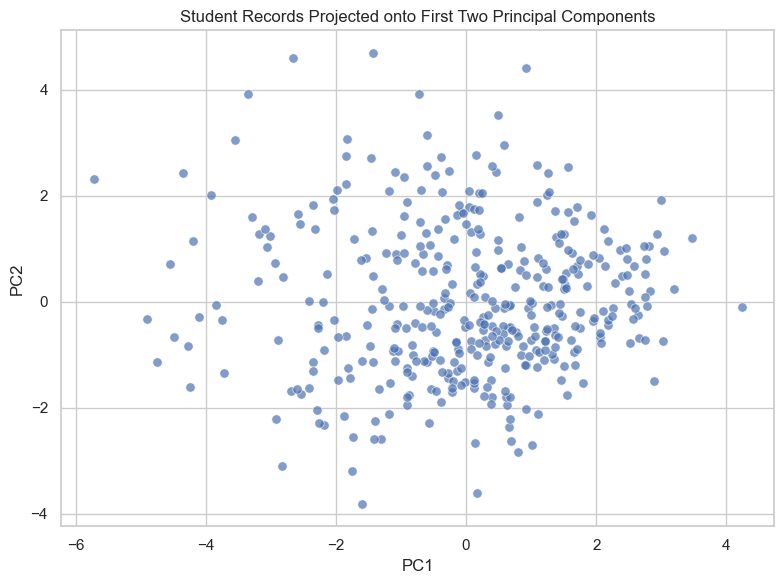

In [4]:
pca_2 = PCA(n_components=2, random_state=42)
X_pca = pca_2.fit_transform(X_scaled)
print("Variance explained by PC1 and PC2:", np.round(pca_2.explained_variance_ratio_, 3))
print("Total variance explained by 2 PCs:", round(pca_2.explained_variance_ratio_.sum(), 3))

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", s=45, alpha=0.7)
plt.title("Student Records Projected onto First Two Principal Components")
plt.tight_layout()
plt.show()

## 5. K-Means: Elbow Method and Silhouette Score

,k,inertia,silhouette_score
0,2,5215.388203,0.126249
1,3,4792.713571,0.107711
2,4,4505.396191,0.096129
3,5,4297.533715,0.091906
4,6,4142.954017,0.085932
5,7,4012.062650,0.080463
6,8,3886.735527,0.079062
7,9,3755.533993,0.084864
8,10,3672.547874,0.082143


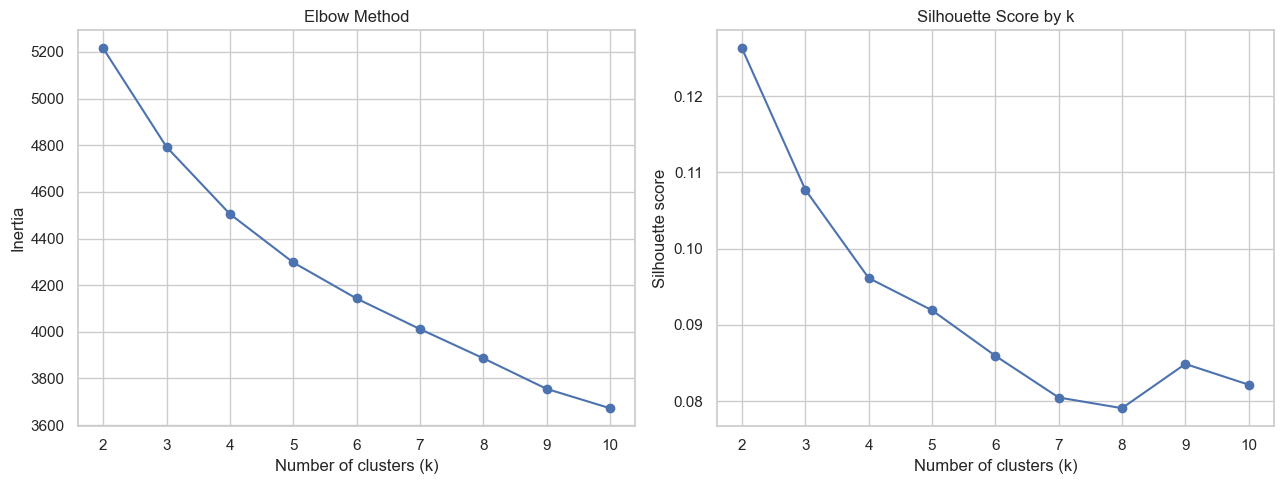

Best k by silhouette score in tested range: 2
Note: compare this with the elbow plot; use domain context, not one metric alone.


In [5]:
# Silhouette is defined only when there are at least 2 clusters and fewer
# clusters than observations. We evaluate a practical range of k values.
ks = range(2, 11)
inertias, silhouettes = [], []
for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

metrics_df = pd.DataFrame({
    "k": list(ks),
    "inertia": inertias,
    "silhouette_score": silhouettes
})
display(metrics_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(metrics_df["k"], metrics_df["inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(metrics_df["k"], metrics_df["silhouette_score"], marker="o")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

best_k = int(metrics_df.loc[metrics_df["silhouette_score"].idxmax(), "k"])
print("Best k by silhouette score in tested range:", best_k)
print("Note: compare this with the elbow plot; use domain context, not one metric alone.")

## 6. Fit K-Means and visualize clusters in PCA space

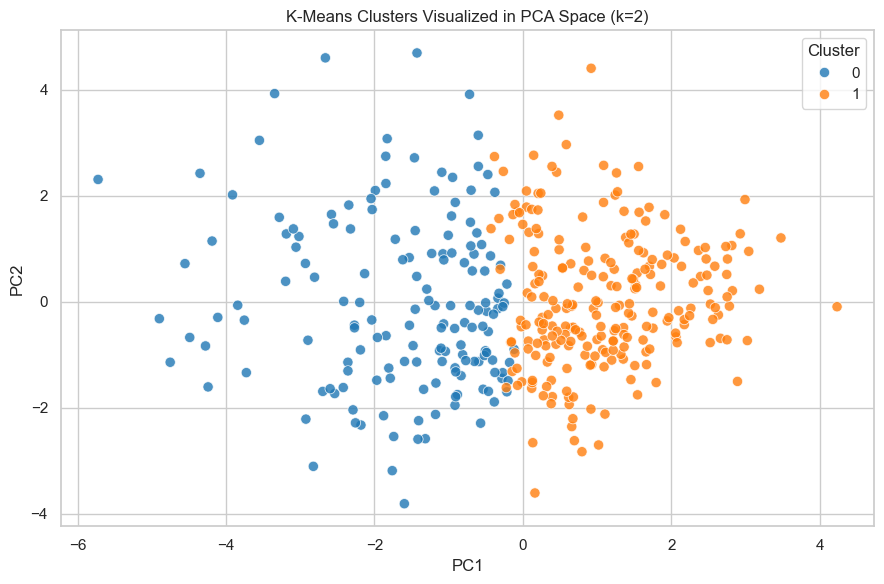

Cluster sizes:


,count
cluster,
0,159
1,236


In [6]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
cluster_plot = pca_df.copy()
cluster_plot["cluster"] = kmeans_labels.astype(str)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=cluster_plot, x="PC1", y="PC2", hue="cluster", palette="tab10", s=55, alpha=0.8)
plt.title(f"K-Means Clusters Visualized in PCA Space (k={best_k})")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print("Cluster sizes:")
display(pd.Series(kmeans_labels, name="cluster").value_counts().sort_index().rename_axis("cluster").to_frame("count"))

## 7. DBSCAN clustering

DBSCAN clusters (excluding noise): 1
Noise points: 390


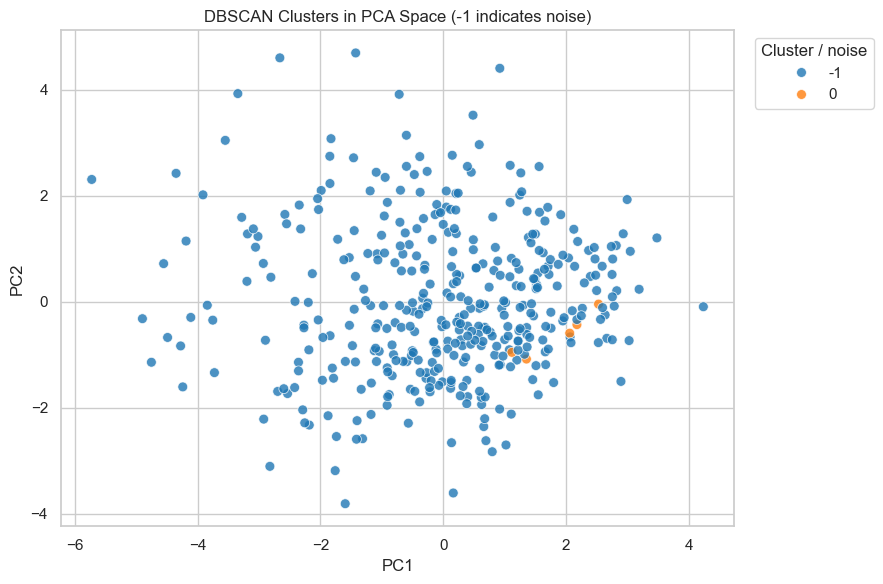

Silhouette not reported: DBSCAN did not produce at least two usable non-noise clusters.


In [7]:
# DBSCAN is density-based; results depend on eps and min_samples.
# These values are a starting point, not a guaranteed optimum.
dbscan = DBSCAN(eps=2.0, min_samples=5)
db_labels = dbscan.fit_predict(X_scaled)
n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = int(np.sum(db_labels == -1))
print("DBSCAN clusters (excluding noise):", n_clusters_db)
print("Noise points:", n_noise)

db_plot = pca_df.copy()
db_plot["cluster"] = db_labels.astype(str)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=db_plot, x="PC1", y="PC2", hue="cluster", palette="tab10", s=50, alpha=0.8)
plt.title("DBSCAN Clusters in PCA Space (-1 indicates noise)")
plt.legend(title="Cluster / noise", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

non_noise = db_labels != -1
valid_db_clusters = set(db_labels[non_noise])
if len(valid_db_clusters) >= 2 and non_noise.sum() > len(valid_db_clusters):
    print("DBSCAN silhouette (excluding noise):", round(silhouette_score(X_scaled[non_noise], db_labels[non_noise]), 3))
else:
    print("Silhouette not reported: DBSCAN did not produce at least two usable non-noise clusters.")

## 8. Hierarchical (Agglomerative) clustering

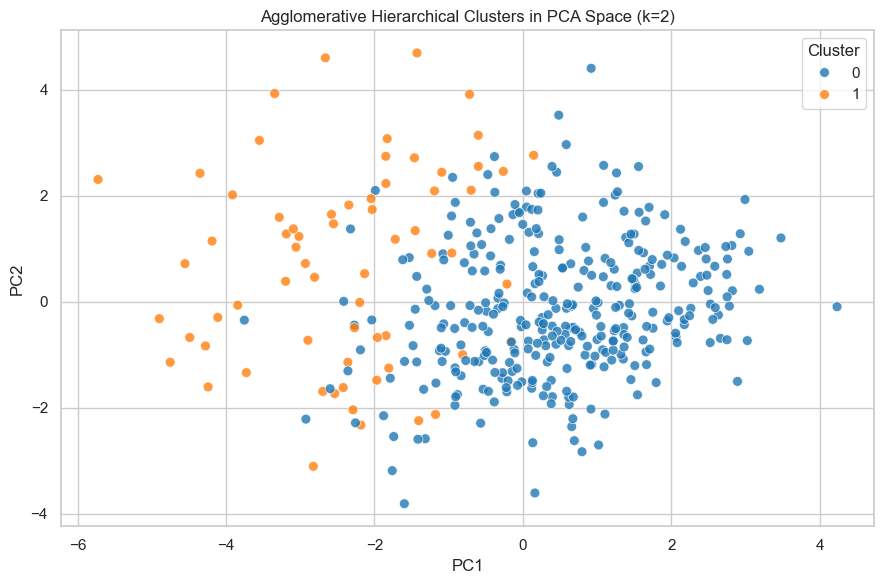

Hierarchical silhouette score: 0.181


In [8]:
# Use the same k chosen for K-Means to compare the partitioning approaches.
hierarchical = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
hier_labels = hierarchical.fit_predict(X_scaled)
hier_plot = pca_df.copy()
hier_plot["cluster"] = hier_labels.astype(str)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=hier_plot, x="PC1", y="PC2", hue="cluster", palette="tab10", s=50, alpha=0.8)
plt.title(f"Agglomerative Hierarchical Clusters in PCA Space (k={best_k})")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()
print("Hierarchical silhouette score:", round(silhouette_score(X_scaled, hier_labels), 3))

## 9. Compare methods and summarize findings

In [9]:
comparison = pd.DataFrame([
    {
        "method": "K-Means",
        "clusters_excluding_noise": len(np.unique(kmeans_labels)),
        "silhouette_score": silhouette_score(X_scaled, kmeans_labels)
    },
    {
        "method": "Agglomerative hierarchical",
        "clusters_excluding_noise": len(np.unique(hier_labels)),
        "silhouette_score": silhouette_score(X_scaled, hier_labels)
    }
])
display(comparison.round(3))

print("PCA summary:")
print(f"- PC1 + PC2 explain {pca_2.explained_variance_ratio_.sum():.1%} of total standardized-feature variance.")
print(f"- {n80} component(s) reach at least 80% cumulative explained variance.")
print("K-Means summary:")
print(f"- Best silhouette k in the tested range: {best_k}.")
print(f"- K-Means silhouette score: {silhouette_score(X_scaled, kmeans_labels):.3f}.")
print("Interpretation guidance:")
print("- A higher silhouette score suggests better separation/cohesion among clusters, but scores can be modest for overlapping real-world data.")
print("- The elbow plot is a heuristic; there may not be one clearly optimal k.")
print("- DBSCAN can label records as noise (-1), and its result depends on eps/min_samples.")
print("- PCA plots show only two dimensions; clusters may overlap in this projection even if higher-dimensional patterns differ.")

,method,clusters_excluding_noise,silhouette_score
0,K-Means,2,0.126
1,Agglomerative hierarchical,2,0.181


PCA summary:
- PC1 + PC2 explain 32.2% of total standardized-feature variance.
- 9 component(s) reach at least 80% cumulative explained variance.
K-Means summary:
- Best silhouette k in the tested range: 2.
- K-Means silhouette score: 0.126.
Interpretation guidance:
- A higher silhouette score suggests better separation/cohesion among clusters, but scores can be modest for overlapping real-world data.
- The elbow plot is a heuristic; there may not be one clearly optimal k.
- DBSCAN can label records as noise (-1), and its result depends on eps/min_samples.
- PCA plots show only two dimensions; clusters may overlap in this projection even if higher-dimensional patterns differ.


## 10. Conclusion (complete after reviewing your output)

After running all cells, write 3–5 sentences using your actual results:
1. How many principal components were needed to reach 80% cumulative explained variance?
2. What value of `k` was suggested by the silhouette score, and did the elbow plot agree?
3. How did K-Means compare with hierarchical clustering by silhouette score?
4. Did DBSCAN identify clusters, noise points, or mostly one group?
5. What are the limitations of using a two-dimensional PCA plot to judge clusters?

Do not claim that a cluster is meaningful without checking the feature patterns within each cluster.